# Advanced Data Preparation with Python (Car Data)

This notebook demonstrates advanced data preparation techniques with pandas using scraped car data from AutoScout24. It is an exercise: complete the empty code cells by applying the steps from the apartment data solution notebook (advanced_data_preparation_apartment_data_solution.ipynb). 
We will cover the following operations:

- Extracting information from raw data using regular expressions
- Counting and removing missing and duplicated values
- Creating new variables using string manipulation
- Discretization and One Hot Encoding
- Scaling and standardization
- Transformations (log, square root, Box-Cox)
- Combining data using .merge()
- Sorting, reshaping and pivoting data

## Libraries and settings

In [1]:
# Libraries
import os                           #Funktionen für Dateien, Ordner und Betriebssystem laden
import re                           #Reguläre Ausdrücke zum Suchen und Extrahieren von Textteilen laden
import time                         #Funktionen für Zeitmessung und Wartepausen laden
import fnmatch                      #Dateinamen mit Mustern wie "*.csv" vergleichen
import numpy as np                  #NumPy für numerische Berechnungen als np laden
import pandas as pd                 #pandas für die Arbeit mit Tabellen als pd laden
import seaborn as sns               #Seaborn für statistische Diagramme als sns laden
from datetime import datetime       #datetime für Datums- und Zeitangaben laden
import matplotlib.pyplot as plt     #Diagrammfunktionen von Matplotlib als plt laden

# Ignore warnings
import warnings                     #Werkzeug zur Steuerung von Warnmeldungen laden
warnings.filterwarnings("ignore")   #Warnmeldungen ausblenden; Fehlermeldungen bleiben sichtbar

# Get current working directory
print(os.getcwd())                  #Aktuellen Arbeitsordner anzeigen

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02


## Importing data

In [2]:
# Import data from csv to pandas dataframe named 'df'
df = pd.read_csv('./autoscout24_data.csv',
                 sep=";",
                 encoding='utf-8')  #CSV aus dem Unterordner Data mit Semikolon als Trennzeichen und UTF-8 einlesen und als df speichern

# Change the column names to lowercase
df.columns = df.columns.str.lower()                                         #Alle Spaltennamen in Kleinbuchstaben umwandeln

# Display the first 5 rows of the dataframe
df.head()                                                                   #Erste fünf Zeilen der Tabelle anzeigen

,url_short,offer_id,scrape_dt,type,price_raw,hp_raw,init_regist,mileage_raw,fuel_type,transmission,dealer_name,dealer_plz,dealer_city,dealer_street_house_nr,dealer_telnr,init_regist_my,init_regist_month,init_regist_year,init_regist_dt
0,https://www.autoscout24.ch/7324420,7324420,2020_03_17 07:34:45,AUDI A5 Sportback 3.0 TDI quattro S-tronic (Li...,CHF 22'500.–,245 PS,10.2014,75'000 km,Diesel,Automatisiertes Schaltgetriebe,***confidential***,8488,Turbenthal,Mettlenstrasse 3,***confidential***,10.2014,10.0,2014.0,2014-10
1,https://www.autoscout24.ch/7512768,7512768,2020_03_17 07:34:55,MERCEDES-BENZ SLK 200 7G-Tronic (Cabriolet),CHF 23'749.–,184 PS,6.2013,46'655 km,Benzin,Automat sequentiell,***confidential***,3186,Düdingen,Brugerastrasse 60,***confidential***,6.2013,6.0,2013.0,2013-06
2,https://www.autoscout24.ch/7512034,7512034,2020_03_17 07:35:03,MERCEDES-BENZ C 350 Avantgarde 4Matic 7G-Troni...,CHF 18'500.–,306 PS,6.2011,138'955 km,Benzin,Automat sequentiell,***confidential***,1262,Eysins,1262 Eysins,***confidential***,6.2011,6.0,2011.0,2011-06
3,https://www.autoscout24.ch/7512728,7512728,2020_03_17 07:35:06,MERCEDES-BENZ A 45 AMG 4Matic Speedshift 7G-DC...,CHF 36'000.–,360 PS,8.2015,43'000 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,4314,Zeiningen,Am Stutz 21,***confidential***,8.2015,8.0,2015.0,2015-08
4,https://www.autoscout24.ch/7490242,7490242,2020_03_17 07:35:16,AUDI A5 Sportback 2.0 TFSI Sport quattro S-tro...,CHF 48'500.–,252 PS,9.2018,43'300 km,Benzin,Automatisiertes Schaltgetriebe,***confidential***,3250,Lyss,3250 Lyss,***confidential***,9.2018,9.0,2018.0,2018-09


## Count number of rows and columns in the data frame

In [3]:
# Count number of rows and columns in the data frame
print("Number of rows: ", df.shape[0])      #Anzahl Zeilen (Datensätze) anzeigen
print("Number of columns: ", df.shape[1])   #Anzahl Spalten (Merkmale) anzeigen

Number of rows:  3980
Number of columns:  19


## Get data types (raw-format from web scraper)

In [4]:
# Get data types of each column
df.dtypes #Datentyp jeder Spalte anzeigen, z. B. int64 für ganze Zahlen oder float64 für Dezimalzahlen

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
dtype: object

## Extract information from raw data using regular expressions (regex)

### Extract numerical values from mileage_raw

In [5]:
# Extract numerical values (note the 'join' function)
mileage = []                                        #Leere Liste für die extrahierten Kilometerstände erstellen
for i in df['mileage_raw']:                         #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"\d+", i)                      #Alle Ziffernfolgen finden; "75'000 km" ergibt ["75", "000"]
    try:                                            #Umwandlung der Treffer in eine ganze Zahl versuchen
        d2 = int(''.join(d1))                       #Treffer verbinden und umwandeln: ["75", "000"] → "75000" → 75000
    except ValueError:                              #Falls keine Ziffern gefunden wurden, scheitert int("")
        d2 = None                                   #Fehlenden Wert verwenden
    mileage.append(d2)                              #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['mileage'] = pd.Series(mileage, dtype="Int64")   #Liste als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['mileage_raw', 'mileage']].head()               #Rohtext und extrahierten Kilometerstand für die ersten fünf Zeilen anzeigen

,mileage_raw,mileage
0,75'000 km,75000
1,46'655 km,46655
2,138'955 km,138955
3,43'000 km,43000
4,43'300 km,43300


### Extract numerical values from hp_raw

In [6]:
# Extract numerical values (note the 'join' function)
hp = []                                     #Leere Liste für die extrahierten PS-Werte erstellen
for i in df['hp_raw']:                      #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"\d+", i)              #Alle Ziffernfolgen finden; "245 PS" ergibt ["245"]
    try:                                    #Umwandlung der Treffer in eine ganze Zahl versuchen
        d2 = int(''.join(d1))               #Treffer verbinden und in eine ganze Zahl umwandeln: ["245"] → 245
    except ValueError:                      #Falls keine Ziffern gefunden wurden, scheitert int("")
        d2 = None                           #Fehlenden Wert verwenden
    hp.append(d2)                           #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['hp'] = pd.Series(hp, dtype="Int64")     #Liste als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['hp_raw', 'hp']].head()                 #Rohtext und extrahierten PS-Wert für die ersten fünf Zeilen anzeigen

,hp_raw,hp
0,245 PS,245
1,184 PS,184
2,306 PS,306
3,360 PS,360
4,252 PS,252


### Extract numerical values from price_raw

In [7]:
# Extract numerical values using a regular expression
price = []                                          #Leere Liste für die extrahierten Preise erstellen
for i in df['price_raw']:                           #Jeden Rohtext durchlaufen; i enthält den aktuellen Text
    d1 = re.findall(r"CHF\s*([\d']+)\.–", i)        #Ziffern und Apostrophe zwischen CHF und .– erfassen; "CHF 22'500.–" ergibt ["22'500"]
    try:                                            #Versuchen, den ersten Treffer zu verarbeiten
        d2 = d1[0].strip().replace("'", "")         #Ersten Treffer nehmen, äusseren Leerraum und Apostrophe entfernen: "22'500" → "22500"
    except IndexError:                              #Falls kein Treffer existiert, scheitert der Zugriff auf d1[0]
        d2 = None                                   #Fehlenden Wert verwenden
    price.append(d2)                                #Ergebnis an die Liste anhängen; ein Eintrag pro Tabellenzeile

# Save as new variable in the pandas data frame
df['price'] = pd.Series(price, dtype="Int64")       #Zahlentexte als neue Ganzzahlspalte speichern; Int64 erlaubt fehlende Werte

# Show first records of data frame
df[['price_raw', 'price']].head()                   #Rohtext und extrahierten Preis für die ersten fünf Zeilen anzeigen

,price_raw,price
0,CHF 22'500.–,22500
1,CHF 23'749.–,23749
2,CHF 18'500.–,18500
3,CHF 36'000.–,36000
4,CHF 48'500.–,48500


### Get data types of all variables, including the new ones

In [8]:
# Get data types of all variables
df.dtypes       #Datentyp jeder Spalte anzeigen, einschliesslich der neu erstellten Spalten

url_short                     str
offer_id                    int64
scrape_dt                     str
type                          str
price_raw                     str
hp_raw                        str
init_regist                   str
mileage_raw                   str
fuel_type                     str
transmission                  str
dealer_name                   str
dealer_plz                  int64
dealer_city                   str
dealer_street_house_nr        str
dealer_telnr                  str
init_regist_my                str
init_regist_month         float64
init_regist_year          float64
init_regist_dt                str
mileage                     Int64
hp                          Int64
price                       Int64
dtype: object

## Count and remove missing values

In [9]:
# Count and remove missing values
print("Missing values before removing: ", df.isnull().sum().sum())
#Fehlende Zellen vor dem Entfernen zählen und Gesamtzahl anzeigen
#isnull(): fehlend = True, entspricht isna(); erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

df = df.dropna()
#Zeilen mit mindestens einem fehlenden Wert entfernen und Ergebnis in df speichern
#dropna(): entfernt standardmässig jede Zeile, die mindestens einen fehlenden Wert enthält

print("Missing values after removing: ", df.isnull().sum().sum())
#Fehlende Zellen nach dem Entfernen zählen; Ergebnis sollte 0 sein
#isnull(): fehlend = True; erstes sum(): Anzahl je Spalte; zweites sum(): Gesamtzahl

# Reset the index of the dataframe
df = df.reset_index(drop=True)
#Verbleibende Zeilen ab 0 neu nummerieren und alten Index verwerfen
#reset_index(): vergibt einen fortlaufenden Index; drop=True: alten Index nicht als Spalte behalten

Missing values before removing:  23
Missing values after removing:  0


## Count and remove duplicated values

In [10]:
# Count and remove duplicates
print("Number of duplicates before removing: ", df.duplicated().sum())
#Zusätzliche Kopien vollständig gleicher Zeilen vor dem Entfernen zählen
#duplicated(): vergleicht alle Spalten, zusätzliche Kopien = True; sum(): True-Werte zählen

df = df.drop_duplicates()
#Duplikate entfernen und Ergebnis in df speichern; erster Eintrag bleibt erhalten
#drop_duplicates(): entfernt standardmässig zusätzliche Kopien vollständig gleicher Zeilen

print("Number of duplicates after removing: ", df.duplicated().sum())
#Verbleibende Duplikate zur Kontrolle zählen; Ergebnis sollte 0 sein
#duplicated().sum(): zählt erneut zusätzliche Kopien vollständig gleicher Zeilen

# Reset the index of the dataframe
df = df.reset_index(drop=True)
#Verbleibende Zeilen ab 0 neu nummerieren und alten Index verwerfen
#reset_index(): vergibt fortlaufenden Index; drop=True: alten Index nicht als Spalte behalten

Number of duplicates before removing:  0
Number of duplicates after removing:  0


## Use string manipulation methods to create additional variables from the car type

### Change strings in 'type' to uppercase

In [11]:
# Change strings in 'type' to uppercase and remove leading/trailing spaces
df['type'] = df['type'].str.upper().str.strip() #Texte in Grossbuchstaben umwandeln, äusseren Leerraum entfernen und zurückspeichern
                                                #.str: Textmethoden anwenden; upper(): Grossbuchstaben; strip(): Leerraum am Anfang und Ende entfernen

# Display variable 'type'
df['type'].head()                               #Erste fünf Werte der bereinigten Spalte type anzeigen

0    AUDI A5 SPORTBACK 3.0 TDI QUATTRO S-TRONIC (LI...
1          MERCEDES-BENZ SLK 200 7G-TRONIC (CABRIOLET)
2    MERCEDES-BENZ C 350 AVANTGARDE 4MATIC 7G-TRONI...
3    MERCEDES-BENZ A 45 AMG 4MATIC SPEEDSHIFT 7G-DC...
4    AUDI A5 SPORTBACK 2.0 TFSI SPORT QUATTRO S-TRO...
Name: type, dtype: str

### Calculate length of strings in 'type'

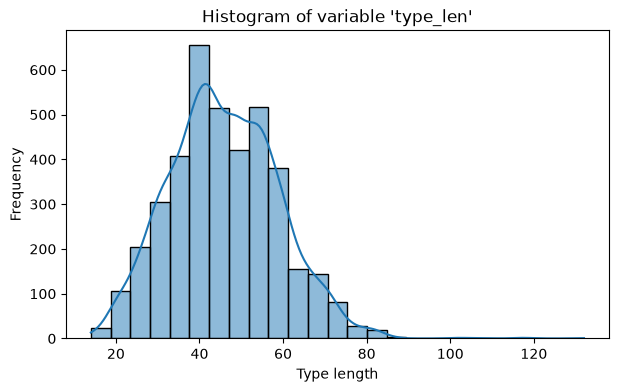

In [12]:
# New variable 'type_len' with the length of strings in 'type' (use .apply())
df['type_len'] = df['type'].apply(len)              #Zeichenanzahl jedes Textes in der neuen Spalte type_len speichern
                                                    #apply(len): wendet len() auf jeden Wert an; zählt auch Leerzeichen und Satzzeichen

# Display variables 'type' and 'type_len'
df[['type', 'type_len']].head()                     #Originaltext und Zeichenanzahl für die ersten fünf Zeilen anzeigen

# Plot histogram of variable 'type_len'
plt.figure(figsize=(7, 4)) #Neue Abbildung mit 7 × 4 Zoll erstellen
sns.histplot(df['type_len'], bins=25, kde=True)     #Textlängen in 25 Intervalle einteilen und Häufigkeiten als Balken darstellen
                                                    #kde=True: geglättete Dichtekurve zur Darstellung der Verteilungsform ergänzen
plt.title("Histogram of variable 'type_len'")       #Diagrammtitel setzen
plt.xlabel('Type length')                           #x-Achse beschriften: Zeichenanzahl der Texte
plt.ylabel('Frequency')                             #y-Achse beschriften: Anzahl Texte je Intervall
plt.show()                                          #Fertiges Diagramm anzeigen

### Create binary (0/1) variable 'luxury_car'

In [13]:
# Create a pattern which can be used to search the variable 'type'
pattern = ('BUGATTI|FERRARI|ROLLS-ROYCE|LAMBORGHINI|BENTLEY|ASTON MARTIN|'      #Gesuchte Luxusmarken festlegen; | bedeutet ODER
           'MASERATI|MCLAREN|PORSCHE')                                          #Python verbindet die beiden Texte automatisch zu einem Suchmuster

# Create new variable 'luxury_car' as binary dummy (0/1) variable
df['luxury_car'] = df['type'].str.contains(pat=pattern).astype(int)             #Enthält die Fahrzeugbezeichnung eine gesuchte Marke, wird luxury_car = 1, sonst 0
                                                                                #str.contains(pat=pattern): sucht die Marken aus pattern; Treffer → True, sonst False
                                                                                #astype(int): wandelt True in 1 und False in 0 um
                                                                                #Die Suche beachtet Gross-/Kleinschreibung: FERRARI trifft, Ferrari nicht

# Count the number of luxury cars
print(df['luxury_car'].sum())                                                   #Einsen addieren und damit die Anzahl der als Luxusauto markierten Fahrzeuge anzeigen

# Show values
df[['type', 'luxury_car']].loc[df['luxury_car'] == 1]                           #Nur Luxusautos mit Fahrzeugbezeichnung und 0/1-Markierung anzeigen
                                                                        #[[...]]: Spalten auswählen; .loc[...]: nur Zeilen behalten, deren luxury_car-Wert 1 ist

299


,type,luxury_car
8,PORSCHE 911 TURBO CABRIO PDK (CABRIOLET),1
26,FERRARI 348 TS (CABRIOLET),1
57,PORSCHE 911 SC (COUPÉ),1
64,PORSCHE 911 CARRERA 4S PDK (COUPÉ),1
65,PORSCHE 911 CARRERA 4S CABRIO (CABRIOLET),1
...,...,...
3933,FERRARI 458 ITALIA 4.5 V8 (COUPÉ),1
3934,FERRARI 458 ITALIA 4.5 V8 (COUPÉ),1
3958,PORSCHE 911 TURBO (S) CABRIO (CABRIOLET),1
3964,BENTLEY ARNAGE RED LABEL (LIMOUSINE),1


### Create variable 'price_per_hp'

In [38]:
# Create variable 'price_per_hp' (round to 2 decimal places)
df['price_per_hp'] = round(df['price'] / df['hp'], 2)   #Preis jedes Autos durch seine PS-Zahl teilen und als neue Spalte speichern
                                                        #round(..., 2): Preis pro PS auf zwei Nachkommastellen runden

# Display variables 'price', 'hp' and 'price_per_hp'
df[['price', 'hp', 'price_per_hp']].head()              #Preis, PS-Zahl und berechneten Preis pro PS für die ersten fünf Zeilen anzeigen
                                                        #[[...]]: Spalten als Tabelle auswählen; head(): erste fünf Zeilen

,price,hp,price_per_hp
0,22500,245,91.84
1,23749,184,129.07
2,18500,306,60.46
3,36000,360,100.0
4,48500,252,192.46


### Include current datetime as time stamp

In [39]:
# Include current datetime as time stamp in the format 'YYYY-MM-DD HH:MM:SS'
df['timestamp'] = datetime.now().strftime('%Y-%m-%d %H:%M:%S')  #Aktuellen Zeitpunkt als Text in jeder Zeile der neuen Spalte timestamp speichern
                                                                #datetime.now(): aktueller Zeitpunkt; strftime(): als Text formatieren
                                                                #%Y-%m-%d: Jahr-Monat-Tag; %H:%M:%S: Stunde:Minute:Sekunde
df['timestamp'].head()                                          #Zeitstempel der ersten fünf Zeilen anzeigen; alle erhalten denselben Zeitpunkt dieses Aufrufs

0    2026-10-15 23:02:54
1    2026-10-15 23:02:54
2    2026-10-15 23:02:54
3    2026-10-15 23:02:54
4    2026-10-15 23:02:54
Name: timestamp, dtype: str

## Discretization of numerical data

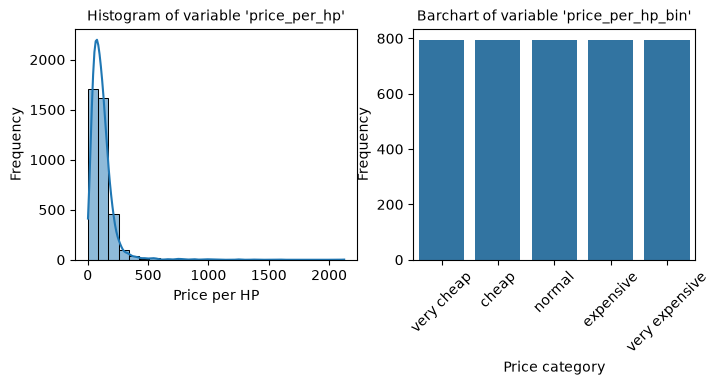

,price_per_hp,price_per_hp_bin
0,91.84,normal
1,129.07,expensive
2,60.46,cheap
3,100.0,normal
4,192.46,very expensive


In [40]:
# Discretization of the variable 'price_per_hp' into 5 bins
# (note the 'qcut' function)
df['price_per_hp_bin'] = pd.qcut(df['price_per_hp'],                    #Preis pro PS in geordnete Klassen einteilen und als neue Spalte speichern
                                 q=5,                                   #Fünf Klassen mit ungefähr gleich vielen Autos bilden; Grenzen anhand der Quantile bestimmen
                                 labels=['very cheap',                  #Beschriftung der niedrigsten Preisklasse
                                         'cheap',                       #Beschriftung der zweiten Klasse
                                         'normal',                      #Beschriftung der mittleren Klasse
                                         'expensive',                   #Beschriftung der vierten Klasse
                                         'very expensive'])             #Beschriftung der höchsten Preisklasse

# Show histogram of price_per_hp and barchart of variable 'price_per_hp_bin'
plt.figure(figsize=(8, 3))                                              #Neue Abbildung mit 8 × 3 Zoll erstellen

# Create a 1x2 grid
plt.subplot(1, 2, 1)                                                    #Raster mit einer Zeile und zwei Diagrammen erstellen; linkes Diagramm auswählen
sns.histplot(df['price_per_hp'], bins=25, kde=True)                     #Numerische Werte in 25 Intervalle einteilen und als Histogramm darstellen
                                                                        #kde=True: geglättete Kurve zur Verteilungsform ergänzen
plt.title("Histogram of variable 'price_per_hp'", fontsize=10)          #Diagrammtitel mit Schriftgrösse 10 setzen
plt.xlabel('Price per HP')                                              #x-Achse: Preis pro PS
plt.ylabel('Frequency')                                                 #y-Achse: Anzahl Autos je Zahlenintervall

plt.subplot(1, 2, 2)                                                    #Rechtes Diagramm im selben Raster auswählen
sns.countplot(data=df, x='price_per_hp_bin', orient='v')                #Autos je Preisklasse zählen und als vertikale Balken darstellen
plt.title("Barchart of variable 'price_per_hp_bin'", fontsize=10)       #Diagrammtitel mit Schriftgrösse 10 setzen
plt.xlabel('Price category')                                            #x-Achse: Preisklassen
plt.ylabel('Frequency')                                                 #y-Achse: Anzahl Autos je Klasse
plt.xticks(rotation=45)                                                 #Beschriftungen der x-Achse um 45 Grad drehen
plt.show()                                                              #Beide Diagramme anzeigen

# Display variables 'price_per_hp' and 'price_per_hp_bin'
df[['price_per_hp', 'price_per_hp_bin']].head()                         #Preis pro PS und zugeordnete Klasse für die ersten fünf Zeilen anzeigen

## One Hot Encoding

In [41]:
# One Hot Encoding of the variable 'price_per_hp_bin'
try:                                                                        #Versuchen, die Kategoriespalte in eigene Dummy-Spalten umzuwandeln
    df = pd.get_dummies(df,                                                 #Ergebnis in df speichern; ursprüngliche Kategoriespalte wird ersetzt
                        columns=['price_per_hp_bin'],                       #Für jede Preiskategorie eine eigene Spalte erstellen
                        drop_first=False)                                   #Alle Kategorien behalten; keine Dummy-Spalte weglassen
except KeyError:                                                            #Falls die angegebene Kategoriespalte nicht vorhanden ist
    print("Dummy variables already exist")                                  #Hinweis ausgeben; die Spalte könnte bereits umgewandelt worden sein
                                                                            #Die Meldung prüft nicht, ob Dummy-Spalten tatsächlich existieren

# Convert boolean values to integers (0 and 1)
dummy_cols = df.filter(like='price_per_hp_bin').columns                     #Namen aller Spalten sammeln, die price_per_hp_bin enthalten
df[dummy_cols] = df[dummy_cols].astype(int)                                 #Dummy-Werte in ganze Zahlen umwandeln: True → 1, False → 0

# Show values of the new dummy variables
df.filter(like='price_per_hp_bin').head()                                   #Erste fünf Zeilen der Dummy-Spalten anzeigen
                                                                            #filter(like=...): Spalten nach Namensteil auswählen; head(): erste fünf Zeilen

,price_per_hp_bin_very cheap,price_per_hp_bin_cheap,price_per_hp_bin_normal,price_per_hp_bin_expensive,price_per_hp_bin_very expensive
0,0,0,1,0,0
1,0,0,0,1,0
2,0,1,0,0,0
3,0,0,1,0,0
4,0,0,0,0,1


## Scaling

### Min-Max Scaling

#### By hand

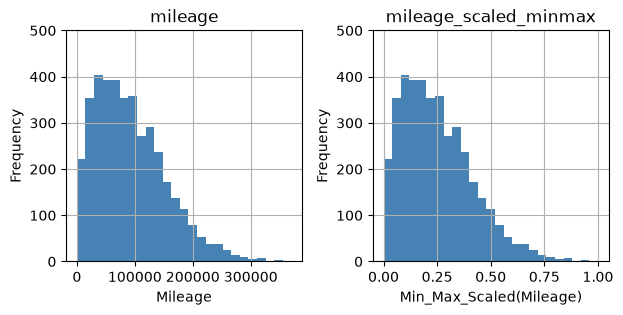

In [42]:
# Min-Max scaling of the variable 'mileage' (by hand)
df['mileage_scaled_minmax'] = ((df['mileage'] - df['mileage'].min())            #Von jedem Kilometerstand den kleinsten Kilometerstand abziehen
                               / (df['mileage'].max() - df['mileage'].min()))   #Durch die Spannweite teilen: grösster minus kleinster Kilometerstand
                                                                                #Ergebnis: kleinster Wert → 0, grösster → 1; übrige Werte dazwischen

# Histogram of the variable 'mileage' and 'mileage_scaled_minmax'
ax = df[['mileage', 'mileage_scaled_minmax']].hist(bins=25,                     #Originalwerte und skalierte Werte als zwei Histogramme darstellen
                                                   figsize=(7, 3),              #Gesamtgrösse der Abbildung: 7 × 3 Zoll
                                                   color='steelblue')           #Balkenfarbe festlegen; ax enthält die Diagrammachsen

# Set the y-axis range for each subplot and add labels
for axis, label in zip(ax.flatten(), ['Mileage', 'Min_Max_Scaled(Mileage)']):   #Jede Diagrammachse mit ihrer zugehörigen Beschriftung durchlaufen
                                                                                #flatten(): Achsenanordnung abflachen; zip(): Achsen und Beschriftungen paarweise verbinden
    axis.set_ylim(0, 500)                                                       #y-Achse auf 0 bis 500 begrenzen
    axis.set_xlabel(label)                                                      #x-Achse mit der jeweils zugehörigen Beschriftung versehen
    axis.set_ylabel('Frequency')                                                #y-Achse beschriften: Anzahl Autos je Intervall

# Display the plot
plt.show()                                                                      #Beide Histogramme anzeigen

#### scikit-learn version

In [19]:
# Min-Max scaling of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Max-Absolute Scaling

#### By hand

In [20]:
# Max-Absolute scaling of the variable 'mileage' (by hand)


# Histogram of the variable 'mileage' and 'mileage_scaled_max_abs'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [21]:
# Max-Absolute scaling of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


### Robust Scaling

#### By hand

In [22]:
# Robust scaling of the variable 'mileage' (by hand)


# Histogram of the variable 'mileage' and 'mileage_scaled_robust'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [23]:
# Robust scaling of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Check that the by-hand and scikit-learn versions give the same result


## Standardization

### Z-score Normalization

#### By hand

In [24]:
# Z-score Normalization of the variable 'mileage' (by hand)


# Histogram of the variable 'mileage' and 'mileage_scaled_z'


# Set the y-axis range for each subplot and add labels


# Display the plot


#### scikit-learn version

In [25]:
# Z-score Normalization of the variable 'mileage' (scikit-learn version)


# Fit the scaler and transform the variable
# (note the double brackets: scikit-learn expects a 2D input)


# Note: pandas .std() divides by n-1, StandardScaler divides by n,
# so the results differ slightly


# Check against the by-hand formula with the standard deviation
# divided by n (ddof=0)


## Transformation

### Log-Transformation

In [26]:
# Log-Transformation of the variable 'mileage'


# Histogram of the variable 'mileage' and 'mileage_log'


# Set the y-axis range for each subplot and add labels


# Display the plot


### SQRT-Transformation

In [27]:
# SQRT-Transformation of the variable 'mileage'


# Histogram of the variable 'mileage' and 'mileage_sqrt'


# Set the y-axis range for each subplot and add labels


# Display the plot


### Box-Cox Transformation

In [28]:
# Import the boxcox function from scipy


# Box-Cox Transformation of the variable 'mileage'


# Histogram of the variable 'mileage' and 'mileage_boxcox'


# Set the y-axis range for each subplot and add labels


# Display the plot


## Combining & organizing data

### Reading car data with geocoded addresses

In [29]:
# Meaning of variables
# offer_id: unique identifier of the offer on autoscout24.ch
# lat: geographical latitude
# lon: geographical longitude
# bfs_number: official municipality id
# bfs_name: official municipality name

# Geocoded data (i.e. data with latitude and longitude)


# Show data


### Join geo-information to car data using .merge()

In [30]:
# Merge geo-information to the car data (the key is 'offer_id')


# Show data


### Reading municipality-level data from an .xlsx - file

In [31]:
# Meaning of variables:
# bfs_number: municipality id
# bfs_name: municipality name
# pop: number of residents
# pop_dens: population density per km2
# frg_pct: percentage foreigners
# emp: number of employees

# Read municipality-level data from the .xlsx file


# Show data


### Join municipality-level data to the car data data using .merge()

In [32]:
# Merge needs a key which must be identical in both data sets
# (here the key is 'bfs_number')


# Show data


### Sorting data

In [33]:
# Sorting data by 'price' and 'mileage' with highest price above
# (ascending=False)


# Show data


### Reshaping data

#### Reshaping data using .stack() and .unstack()

In [34]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .stack()


# Reshape the data back using .unstack()


#### Reshaping data using .melt()

In [35]:
# Create a subset of the data (first 5 rows)


# Reshape the data using .melt()


### Pivoting data using .pivot_table()

In [36]:
# Create a pivot table with the mean values per fuel type


# Format the values to 2 decimal places with trailing zeros


# Display the pivot table


### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [37]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1064-azure
Datetime: 2026-10-15 22:28:47
Python Version: 3.12.11
-----------------------------------
